# 08 · Libre de riesgo, baselines y costes (bloque 8)

Este notebook recorre las tres piezas que necesita el agente de cartera para compararse con algo honesto:

1. **Tipo libre de riesgo**: `fred:DTB3` punto en el tiempo (publicado en T+1) es el que ven los agentes; el RF
   diario de Ken French (`ff:F3D.RF`) solo sirve para evaluar *ex post*; en EUR, EONIA→€STR (bloque 4).
2. **Baselines** calculados solo con `get_precios` en cada fecha de control (último día hábil del mes, 16:30 de
   Nueva York), sin mirar al futuro: buy&hold SPY y RSP, 60/40 SPY/AGG (VBMFX antes de 2003-09), 1/N mensual sobre
   los ETF del núcleo, momentum sectorial 12-1 top 3 de los SPDR y el 60/40 europeo (anexo).
3. **Costes**: comisiones DEGIRO (10.000 €) e IBKR (sensibilidad), 0,25 % de FX y medio spread base por clase ×
   multiplicador de crisis `m_t = clip(CHL_21d / mediana en calma, 1, 10)`.

Las curvas se calculan con `python -m ingesta.mercados_series.cartera.informe --parte brutos|costes` y viven en el
corpus (`<corpus>/mercados_series/cartera/`), no en el repositorio. Aquí solo hay gráficos.

In [1]:
%matplotlib inline
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ingesta.comun.rutas import corpus_dir
from ingesta.mercados_series import almacen
from ingesta.mercados_series.cartera import costes as c
from ingesta.mercados_series.cartera import libre_riesgo as lr

try:
    from regimenes import viz
    viz.use_house_style()
except Exception:  # sin el paquete de la Fase 1: estilo por defecto de matplotlib
    pass
plt.rcParams['figure.dpi'] = 80
warnings.filterwarnings('ignore', category=FutureWarning)

CARPETA = corpus_dir('mercados_series') / 'cartera'
BRUTOS = pd.read_parquet(CARPETA / 'baselines_brutos.parquet')
COSTES = pd.read_parquet(CARPETA / 'baselines_costes.parquet')
MULT = pd.read_parquet(CARPETA / 'multiplicador_spy.parquet')
MED = {p: json.loads((CARPETA / f'mediciones_{p}.json').read_text(encoding='utf-8')) for p in ('brutos', 'costes')}
print(f"curvas brutas: {BRUTOS['estrategia'].nunique()} estrategias; con costes: {COSTES.groupby(['estrategia', 'variante']).ngroups}")

curvas brutas: 5 estrategias; con costes: 7


## 1. Libre de riesgo: DTB3 visible frente a French RF ex post

DTB3 se cotiza en % de descuento; se pasa a rendimiento equivalente de bono y se toma el último dato con
`fecha_publicacion <= d`. French RF es la letra a 1 mes, diaria y compuesta: se anualiza con una ventana de 21
sesiones. La diferencia es pequeña salvo en tensiones del mercado monetario (las letras a 1 mes caen más en las
huidas a la calidad), y French solo existe con meses de retraso: no puede entrar en una decisión.

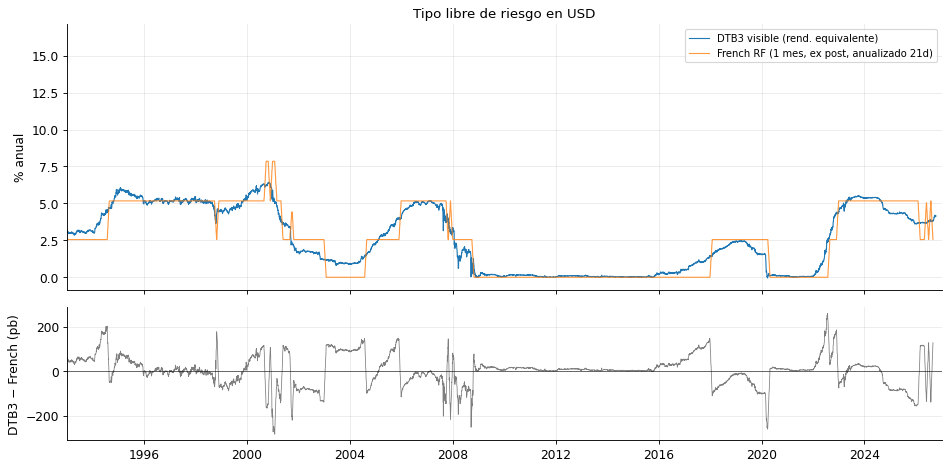

días entre referencia y visibilidad de DTB3: mediana 1, p95 3
EUR: ['empalme EONIA→€STR en la primera fecha con €STR visible, sin sumar los 8,5 pb del diferencial oficial']


In [2]:
base = almacen.leer_series([lr.SERIE_DTB3, lr.SERIE_FRENCH_RF])
dias = pd.bdate_range('1993-01-04', '2026-10-12')
dtb3 = lr.tasa_dtb3(dias, base=base)
fr = lr.rf_french(base)
fr_anual = (1 + fr).rolling(21).apply(np.prod, raw=True) ** (252 / 21) - 1
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
ax[0].plot(dtb3.index, dtb3['rendimiento'] * 100, lw=1, label='DTB3 visible (rend. equivalente)')
ax[0].plot(fr_anual.index, fr_anual * 100, lw=1, alpha=0.8, label='French RF (1 mes, ex post, anualizado 21d)')
ax[0].set_ylabel('% anual'); ax[0].legend(loc='upper right'); ax[0].set_title('Tipo libre de riesgo en USD')
dif = (dtb3['rendimiento'].reindex(fr_anual.index) - fr_anual).dropna() * 1e4
ax[1].plot(dif.index, dif, lw=0.7, color='tab:gray'); ax[1].axhline(0, color='k', lw=0.5)
ax[1].set_ylabel('DTB3 − French (pb)'); ax[1].set_xlim(pd.Timestamp('1993-01-01'), pd.Timestamp('2026-12-31'))
plt.tight_layout(); plt.show()
ret = (dtb3['fecha_publicacion'] - dtb3['fecha_referencia']).dt.days
print(f'días entre referencia y visibilidad de DTB3: mediana {ret.median():.0f}, p95 {ret.quantile(0.95):.0f}')
eur = lr.tasa_eur(dias[-3:])
print('EUR:', eur.attrs.get('avisos'))

## 2. Curvas de capital y drawdowns de los baselines (sin costes)

Cada curva empieza el primer día en que la estrategia puede invertir (SPY en 1993-01, RSP en 2003-05, momentum en
1999-12 con 12 meses de historia). Escala logarítmica, base 1 en su inicio.

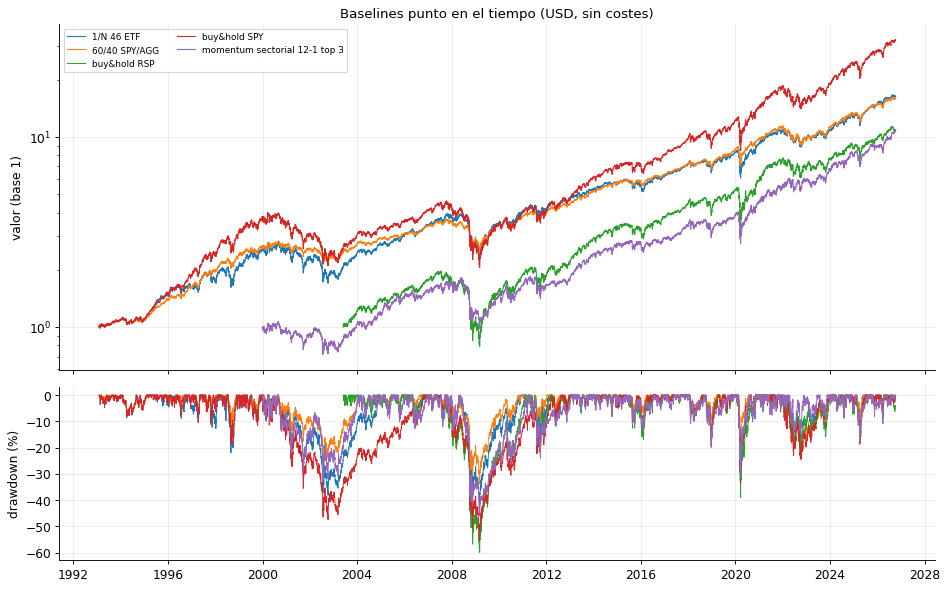

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
for nombre, d in BRUTOS.groupby('estrategia'):
    s = d.set_index('fecha')['valor_usd']
    if len(s) < 2:
        continue
    ax[0].plot(s.index, s / s.iloc[0], lw=1, label=nombre)
    ax[1].plot(s.index, (s / s.cummax() - 1) * 100, lw=0.8)
ax[0].set_yscale('log'); ax[0].set_ylabel('valor (base 1)'); ax[0].legend(fontsize=8, ncol=2)
ax[0].set_title('Baselines punto en el tiempo (USD, sin costes)')
ax[1].set_ylabel('drawdown (%)')
plt.tight_layout(); plt.show()

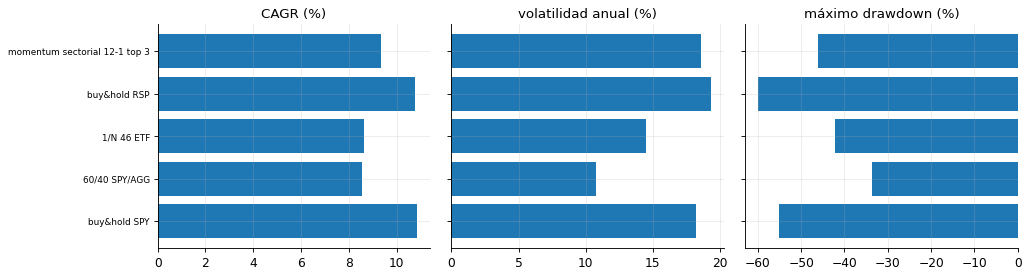

estrategias sin curva (sin precios): ['60/40 UCITS CSPX.L/EUNA.DE']


In [4]:
m = pd.DataFrame(MED['brutos']['metricas']).T
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ok = m[m['cagr'].notna()] if 'cagr' in m else m.iloc[:0]
for a, col, tit in zip(ax, ['cagr', 'vol', 'max_drawdown'], ['CAGR', 'volatilidad anual', 'máximo drawdown']):
    a.barh(ok.index, ok[col].astype(float) * 100, color='tab:blue'); a.set_title(f'{tit} (%)')
    a.tick_params(axis='y', labelsize=8)
for a in ax[1:]:
    a.set_yticklabels([])
plt.tight_layout(); plt.show()
sin = [k for k, v in MED['brutos']['metricas'].items() if not v.get('cagr')]
print('estrategias sin curva (sin precios):', sin)

## 3. Sensibilidad a costes

60/40 y momentum con DEGIRO (caso base: 10.000 € iniciales, comisión fija por orden, 0,25 % de FX porque los ETF
cotizan en USD), IBKR (por acción, FX casi nulo) y DEGIRO sin multiplicador de crisis. La comisión fija pesa mucho
con un patrimonio pequeño y una rotación mensual: el momentum lo nota más que el 60/40.

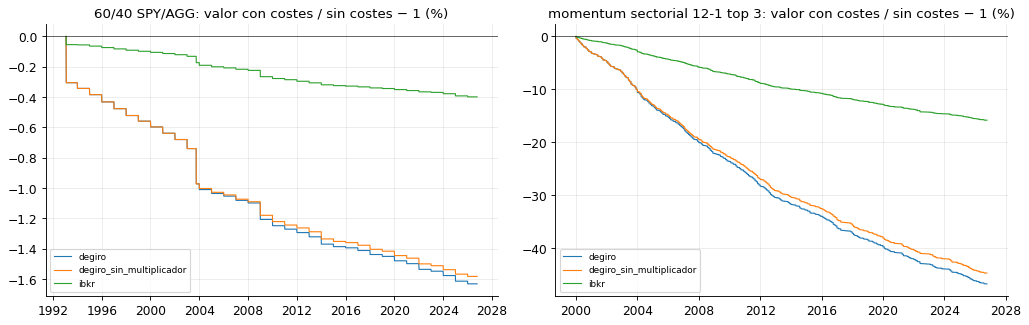

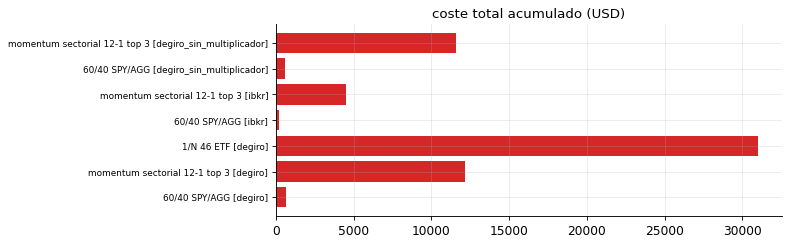

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, est in zip(ax, ['60/40 SPY/AGG', 'momentum sectorial 12-1 top 3']):
    bruto = BRUTOS[BRUTOS['estrategia'] == est].set_index('fecha')['valor_usd']
    for var, d in COSTES[COSTES['estrategia'] == est].groupby('variante'):
        s = d.set_index('fecha')['valor_usd']
        b0 = bruto.reindex(s.index).ffill()
        a.plot(s.index, (s / s.iloc[0]) / (b0 / b0.iloc[0]) * 100 - 100, lw=1, label=var)
    a.set_title(f'{est}: valor con costes / sin costes − 1 (%)'); a.legend(fontsize=8); a.axhline(0, color='k', lw=0.5)
plt.tight_layout(); plt.show()
cm = pd.DataFrame(MED['costes']['costes']).T
fig, a = plt.subplots(figsize=(10, 3.2))
a.barh(cm.index, cm['coste_total_usd'].astype(float), color='tab:red'); a.set_title('coste total acumulado (USD)')
a.tick_params(axis='y', labelsize=8); plt.tight_layout(); plt.show()

## 4. Multiplicador de crisis (SPY): 2008 y 2020

`CHL_21d` es el estimador de Abdi-Ranaldo (cierre, máximo, mínimo) medio de 21 sesiones sobre el OHLC as-traded de
SPY; Corwin-Schultz se muestra como contraste. La calma son las sesiones con volatilidad de 21 días por debajo de
su mediana expansiva y la referencia es la mediana expansiva del CHL en calma: todo usa solo sesiones pasadas. En
calma el estimador sale a menudo negativo (se trunca a 0), así que `m` se queda en 1 la mayor parte del tiempo.

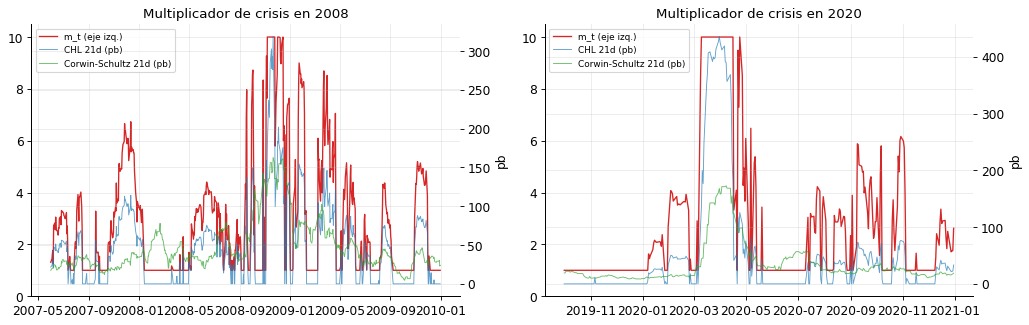

{"calma_2017": {"m_media": 1.4, "m_mediana": 1.03, "chl_mediana_pb": 14.5}, "crisis_2008": {"m_media": 5.73, "m_mediana": 6.9, "chl_mediana_pb": 118.4}, "covid_2020": {"m_media": 7.29, "m_mediana": 10.0, "chl_mediana_pb": 190.3}}


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, (ini, fin, tit) in zip(ax, [('2007-06-01', '2009-12-31', '2008'), ('2019-10-01', '2020-12-31', '2020')]):
    d = MULT.loc[ini:fin]
    a.plot(d.index, d['m'], color='tab:red', lw=1.2, label='m_t (eje izq.)')
    a.set_ylim(0, 10.5); a.set_title(f'Multiplicador de crisis en {tit}')
    b2 = a.twinx()
    b2.plot(d.index, d['chl_21d'] * 1e4, color='tab:blue', lw=0.8, alpha=0.7, label='CHL 21d (pb)')
    b2.plot(d.index, d['cs_21d'] * 1e4, color='tab:green', lw=0.8, alpha=0.7, label='Corwin-Schultz 21d (pb)')
    b2.set_ylabel('pb')
    h1, l1 = a.get_legend_handles_labels(); h2, l2 = b2.get_legend_handles_labels()
    a.legend(h1 + h2, l1 + l2, fontsize=8, loc='upper left')
plt.tight_layout(); plt.show()
print(json.dumps(MED['costes']['multiplicador_spy']['periodos'], ensure_ascii=False))

## 5. Qué queda pendiente

- **EUR**: EONIA/€STR del bloque 4 aún no están en la base; Euribor 3M no está catalogado.
- **60/40 europeo**: sin precios de los UCITS (CSPX.L, EUNA.DE) no se calcula; la función está lista.
- **Comisiones**: tarifas públicas de DEGIRO e IBKR anotadas sin verificar (`verificado=False` en
  `tablas/costes_modelo.csv`).
- **Supervivencia**: el universo 1/N es la lista estática del núcleo de Yahoo (ETF que existen hoy).